In [64]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

## Please use correct dataset path in the DATASET_PATH variable.

In [ ]:
DATASET_PATH = Path("../data/iavd_ml_dataset.parquet")

In [33]:
if not DATASET_PATH.exists():
    raise FileNotFoundError(f"No dataset found at: {DATASET_PATH.resolve()}")

df = pd.read_parquet(DATASET_PATH)

In [34]:
df.head()

,EntityId,Дата создания,Создан,Дата,Вердикт,Дата закрытия (факт),Попытка эксплуатации,Тип инцидента,Список вредоносных команд,Критичность,...,Легитимность действия,Открыт для редактирования,Белый список,Ложное срабатывание,Инцидент был изменен,Время решения,SLA по устранению Атаки,SLA по взятию в работу Атаки,Период взятия в работу,задержка перед автоназначением
0,7291,2024-04-12 14:07:34.000000+00:00,2024-04-12 14:07:34+00,2024-04-12,Закрыт из родительской атаки,NaN,NaN,"[""Общий Инцидент ИБ""]",NaN,Низкая,...,false,NaN,NaN,NaN,false,2245494794.7944,28800000,21600000,588332722.9802,NaN
1,182208,2024-05-07 11:13:58.000000+00:00,2024-05-07 11:13:58+00,2024-05-07,NaN,NaN,NaN,"[""Вирус не вылечен"", ""Подозрительный трафик""]",NaN,Средняя,...,false,false,NaN,NaN,false,0,28800000,21600000,0,NaN
2,183487,2024-05-16 08:37:19.000000+00:00,2024-05-16 08:37:19+00,2024-05-16,NaN,NaN,NaN,"[""Общий Инцидент ИБ""]",NaN,Низкая,...,false,false,NaN,NaN,false,33295.125,28800000,21600000,951437632.7383,NaN
3,183488,2024-05-16 08:37:17.999999+00:00,2024-05-16 08:37:18+00,2024-05-16,NaN,NaN,NaN,"[""Общий Инцидент ИБ""]",NaN,Низкая,...,false,false,NaN,NaN,false,0,86400000,28800000,0,NaN
4,183489,2024-05-16 08:37:11.000000+00:00,2024-05-16 08:37:11+00,2024-05-16,NaN,NaN,NaN,"[""Общий Инцидент ИБ""]",NaN,Низкая,...,false,false,NaN,NaN,false,0,86400000,28800000,0,NaN


## Please use correct mini-dataset path in the SOC_DATASET_PATH variable.

In [13]:
SOC_DATASET_PATH = Path("../data/new_incidents_soc_1000.parquet")

In [35]:
if not SOC_DATASET_PATH.exists():
    raise FileNotFoundError(f"No dataset found at: {SOC_DATASET_PATH.resolve()}")

# Загружаем маленький датасет
df_soc = pd.read_parquet(SOC_DATASET_PATH)
# Исключаем его записи из большого датасета
df = df[
    ~df["EntityId"].isin(df_soc["EntityId"])
].copy()

In [36]:
# эти поля заполняются аналитиками ИБ в ходе расследования/ЖЦ
# необходимо их исключить из признаков, тк они дублируют таргет

columns_c = [
    "Дата закрытия (факт)",
    "Дата закрытия",
    "Дата взятия в работу",
    "Время Решения",
    "Время решения",
    "Период взятия в работу",
    "Ответсвенный по РП",
    "Группа устранения",
    "Фаза реагирования",
    "Статус инцидента из SIEM",
    "Ответственный",
    "Прошлый ответственный",
    "Полное имя",
    "Принятые меры",
    "Рекомендации по плейбуку",
    "Комментарий",
    "Решение",
    "Ошибки",
    "Ссылка в NAD (actual)",
    "Спам",
    "Эскалировался на L2?",
    "Пауза",
    "На мониторинг",
    "Заблокировать",
    "SLA просрочен (взятие в работу)",
    "Проверка на FP выполнена",
    "Выполнено первичное сдерживание",
    "Обогащение выполнено",
    "Классификация выполнена",
    "Успех brute force",
    "False Positive",
    "Легитимность действия",
    "Открыт для редактирования",
    "Белый список",
    "Ложное срабатывание",
    "Инцидент был изменен"
]

In [37]:
existing_c = [col for col in columns_c if col in df.columns]
df_new = df.drop(columns=existing_c)
df_new.head()

,EntityId,Дата создания,Создан,Дата,Вердикт,Попытка эксплуатации,Тип инцидента,Список вредоносных команд,Критичность,Пиктограмма IRP,...,Количество инцидентов,dst,src,Время первого события,Время последнего события,Дата создания в источнике,Дата изменения в источнике,SLA по устранению Атаки,SLA по взятию в работу Атаки,задержка перед автоназначением
0,7291,2024-04-12 14:07:34.000000+00:00,2024-04-12 14:07:34+00,2024-04-12,Закрыт из родительской атаки,NaN,"[""Общий Инцидент ИБ""]",NaN,Низкая,Управление УЗ,...,5,NaN,NaN,2024-04-12 13:52:30+00,2024-04-12 14:04:41+00,2024-04-12 14:07:34+00,2024-04-27 05:49:58+00,28800000,21600000,NaN
1,182208,2024-05-07 11:13:58.000000+00:00,2024-05-07 11:13:58+00,2024-05-07,NaN,NaN,"[""Вирус не вылечен"", ""Подозрительный трафик""]",NaN,Средняя,Вредоносное ПО,...,2,NaN,NaN,2024-05-07 11:04:00+00,2024-05-07 11:22:31+00,2024-05-07 11:13:58+00,2024-05-07 13:40:46+00,28800000,21600000,NaN
2,183487,2024-05-16 08:37:19.000000+00:00,2024-05-16 08:37:19+00,2024-05-16,NaN,NaN,"[""Общий Инцидент ИБ""]",NaN,Низкая,Управление УЗ,...,NaN,NaN,NaN,2024-05-16 08:30:24+00,2024-05-16 08:30:24+00,2024-05-16 08:37:19+00,2024-05-16 08:36:43+00,28800000,21600000,NaN
3,183488,2024-05-16 08:37:17.999999+00:00,2024-05-16 08:37:18+00,2024-05-16,NaN,NaN,"[""Общий Инцидент ИБ""]",NaN,Низкая,Управление УЗ,...,NaN,NaN,NaN,2024-05-16 08:30:23+00,2024-05-16 08:30:23+00,2024-05-16 08:37:18+00,2024-05-16 08:36:45+00,86400000,28800000,NaN
4,183489,2024-05-16 08:37:11.000000+00:00,2024-05-16 08:37:11+00,2024-05-16,NaN,NaN,"[""Общий Инцидент ИБ""]",NaN,Низкая,Управление УЗ,...,NaN,NaN,NaN,2024-05-16 08:30:20+00,2024-05-16 08:30:20+00,2024-05-16 08:37:11+00,2024-05-16 08:36:50+00,86400000,28800000,NaN


In [38]:
df_new = df_new.drop_duplicates()

constant_cols = [col for col in df_new.columns if df_new[col].nunique(dropna=True) <= 1]
df_new = df_new.drop(columns=constant_cols)

In [39]:
df_new.head()

,EntityId,Дата создания,Создан,Дата,Вердикт,Тип инцидента,Список вредоносных команд,Критичность,Пиктограмма IRP,Типы угроз,...,Количество инцидентов,dst,src,Время первого события,Время последнего события,Дата создания в источнике,Дата изменения в источнике,SLA по устранению Атаки,SLA по взятию в работу Атаки,задержка перед автоназначением
0,7291,2024-04-12 14:07:34.000000+00:00,2024-04-12 14:07:34+00,2024-04-12,Закрыт из родительской атаки,"[""Общий Инцидент ИБ""]",NaN,Низкая,Управление УЗ,NaN,...,5,NaN,NaN,2024-04-12 13:52:30+00,2024-04-12 14:04:41+00,2024-04-12 14:07:34+00,2024-04-27 05:49:58+00,28800000,21600000,NaN
1,182208,2024-05-07 11:13:58.000000+00:00,2024-05-07 11:13:58+00,2024-05-07,NaN,"[""Вирус не вылечен"", ""Подозрительный трафик""]",NaN,Средняя,Вредоносное ПО,"[""Хакерское ПО"", ""Админское ПО""]",...,2,NaN,NaN,2024-05-07 11:04:00+00,2024-05-07 11:22:31+00,2024-05-07 11:13:58+00,2024-05-07 13:40:46+00,28800000,21600000,NaN
2,183487,2024-05-16 08:37:19.000000+00:00,2024-05-16 08:37:19+00,2024-05-16,NaN,"[""Общий Инцидент ИБ""]",NaN,Низкая,Управление УЗ,NaN,...,NaN,NaN,NaN,2024-05-16 08:30:24+00,2024-05-16 08:30:24+00,2024-05-16 08:37:19+00,2024-05-16 08:36:43+00,28800000,21600000,NaN
3,183488,2024-05-16 08:37:17.999999+00:00,2024-05-16 08:37:18+00,2024-05-16,NaN,"[""Общий Инцидент ИБ""]",NaN,Низкая,Управление УЗ,NaN,...,NaN,NaN,NaN,2024-05-16 08:30:23+00,2024-05-16 08:30:23+00,2024-05-16 08:37:18+00,2024-05-16 08:36:45+00,86400000,28800000,NaN
4,183489,2024-05-16 08:37:11.000000+00:00,2024-05-16 08:37:11+00,2024-05-16,NaN,"[""Общий Инцидент ИБ""]",NaN,Низкая,Управление УЗ,NaN,...,NaN,NaN,NaN,2024-05-16 08:30:20+00,2024-05-16 08:30:20+00,2024-05-16 08:37:11+00,2024-05-16 08:36:50+00,86400000,28800000,NaN


In [40]:
df_new["Вердикт"].value_counts(dropna=False)

Вердикт
False Positive                       166527
NaN                                   54517
Решён                                 30442
Дубликат                               6043
SPAM                                    363
Не решён                                317
Закрыт по совокупности инцидентов         8
Закрыт из родительской атаки              1
Name: count, dtype: int64

In [41]:
#предлагается решить задачу бинарной классификации, поэтому нужно оставить 
#только Решён и False Positive
df_new = df_new[df_new["Вердикт"].isin(["Решён", "False Positive"])].copy()

In [42]:
df_new["y"] = df_new["Вердикт"].map({"Решён": 1, "False Positive": 0})

In [43]:
df_new.dtypes

EntityId                                                  int64
Дата создания                               datetime64[us, UTC]
Создан                                                      str
Дата                                                     object
Вердикт                                                     str
Тип инцидента                                               str
Список вредоносных команд                                   str
Критичность                                                 str
Пиктограмма IRP                                             str
Типы угроз                                                  str
Теги                                                        str
Источник инцидента                                          str
Вендор из сием                                              str
Организация                                                 str
Наименование                                                str
suser                                   

In [44]:
df_new.dtypes.to_string()

'EntityId                                                  int64\nДата создания                               datetime64[us, UTC]\nСоздан                                                      str\nДата                                                     object\nВердикт                                                     str\nТип инцидента                                               str\nСписок вредоносных команд                                   str\nКритичность                                                 str\nПиктограмма IRP                                             str\nТипы угроз                                                  str\nТеги                                                        str\nИсточник инцидента                                          str\nВендор из сием                                              str\nОрганизация                                                 str\nНаименование                                                str\nsuser                   

In [45]:
date_cols = [
    "Создан",
    "Время первого события",
    "Время последнего события",
    "Дата создания в источнике",
    "Дата изменения в источнике"]

for col in date_cols:
    if col in df_new.columns:
        df_new[col] = pd.to_datetime(
            df_new[col],
            errors="coerce",
            utc=True
        )



In [46]:
numeric_cols = [
    "Количество инцидентов",
    "SLA по устранению Атаки",
    "SLA по взятию в работу Атаки",
    "задержка перед автоназначением"
]

for col in numeric_cols:
    if col in df_new.columns:
        df_new[col] = pd.to_numeric(
            df_new[col],
            errors="coerce"
        )

In [47]:
df_new["hour"] = df_new["Создан"].dt.hour
df_new["day_of_week"] = df_new["Создан"].dt.dayofweek
df_new["month"] = df_new["Создан"].dt.month

C:\Users\user\AppData\Local\Temp\ipykernel_8124\1482581010.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_new["day_of_week"] = df_new["Создан"].dt.dayofweek


In [48]:
# продолжительность события:
df_new["event_duration_hours"] = (df_new["Время последнего события"]
                                  - df_new["Время первого события"]).dt.total_seconds() / 3600

# упоминаются выбросы в датах, которые желательно убрать
threshold = pd.Timestamp("2024-04-12", tz="UTC")

invalid = ((df_new["Время первого события"] < threshold) | (df_new["event_duration_hours"] < 0))
df_new.loc[invalid, "event_duration_hours"] = float("nan")

In [49]:
#время между созданием события в источнике и регистрацией карточки в SOAR
df_new["siem_soar_delay_hours"] = (df_new["Создан"]
                                    - df_new["Дата создания в источнике"]
).dt.total_seconds() / 3600

In [50]:
numeric_features = ["Количество инцидентов", "SLA по устранению Атаки", "SLA по взятию в работу Атаки", "задержка перед автоназначением", 
"hour", "day_of_week", "month", "event_duration_hours", "siem_soar_delay_hours"]

categorical_features = ["Критичность", "Источник инцидента", "Наименование", "Пиктограмма IRP"]

numeric_features = [
    col for col in numeric_features
    if col in df_new.columns
]

categorical_features = [
    col for col in categorical_features
    if col in df_new.columns
]

In [51]:
features = numeric_features + categorical_features
X = df_new[features]
y = df_new["y"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

In [52]:
for X_part in [X_train, X_val, X_test]:
    for col in numeric_features:
        X_part[col] = pd.to_numeric(
            X_part[col], errors="coerce"
        )
        X_part[col] = X_part[col].replace(
            [np.inf, -np.inf], np.nan
        )

    for col in categorical_features:
        X_part[col] = (
            X_part[col]
            .fillna("Missing")
            .astype(str)
        )

In [53]:
%pip install catboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
from catboost import CatBoostClassifier

model = CatBoostClassifier(iterations=1000, depth=6, learning_rate=0.05, loss_function="Logloss", 
                           eval_metric="AUC", auto_class_weights="Balanced", random_seed=42, verbose=100)

model.fit(X_train, y_train, cat_features=categorical_features, eval_set=(X_val, y_val), early_stopping_rounds=100)

0:	test: 0.8001608	best: 0.8001608 (0)	total: 208ms	remaining: 3m 28s
100:	test: 0.8581044	best: 0.8581044 (100)	total: 20.8s	remaining: 3m 5s
200:	test: 0.8735216	best: 0.8735216 (200)	total: 40.8s	remaining: 2m 42s
300:	test: 0.8854662	best: 0.8854662 (300)	total: 1m 1s	remaining: 2m 22s
400:	test: 0.8930962	best: 0.8930962 (400)	total: 1m 21s	remaining: 2m 1s
500:	test: 0.8985745	best: 0.8985745 (500)	total: 1m 41s	remaining: 1m 41s
600:	test: 0.9027040	best: 0.9027040 (600)	total: 2m 2s	remaining: 1m 21s
700:	test: 0.9060599	best: 0.9060599 (700)	total: 2m 23s	remaining: 1m 1s
800:	test: 0.9087195	best: 0.9087195 (800)	total: 2m 44s	remaining: 40.9s
900:	test: 0.9110757	best: 0.9110757 (900)	total: 3m 6s	remaining: 20.5s
999:	test: 0.9132657	best: 0.9132657 (999)	total: 3m 27s	remaining: 0us

bestTest = 0.9132656583
bestIteration = 999



CatBoostClassifier(auto_class_weights='Balanced', depth=6, eval_metric='AUC', iterations=1000, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=100)

In [55]:
val_proba = model.predict_proba(X_val)[:, 1]
results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    y_pred = (val_proba >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "Predicted positive": y_pred.sum()
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Threshold,Precision,Recall,F1,Predicted positive
0,0.1,0.253,0.987,0.403,17813
1,0.2,0.297,0.976,0.456,15003
2,0.3,0.337,0.956,0.498,12946
3,0.4,0.386,0.922,0.544,10918
4,0.5,0.440,0.870,0.584,9030
5,0.6,0.503,0.786,0.613,7138
6,0.7,0.602,0.676,0.636,5128
7,0.8,0.703,0.500,0.585,3251
8,0.9,0.846,0.215,0.342,1158


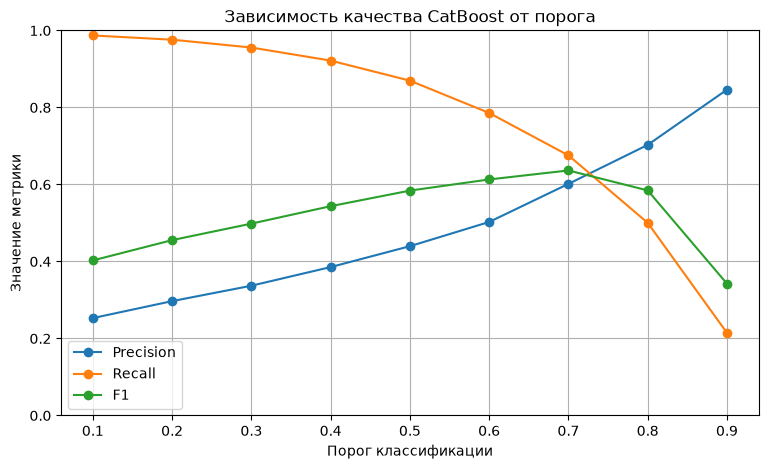

In [56]:
plt.figure(figsize=(9, 5))

plt.plot(results_df["Threshold"], results_df["Precision"], marker="o", label="Precision")
plt.plot(results_df["Threshold"], results_df["Recall"], marker="o", label="Recall")

plt.plot(results_df["Threshold"], results_df["F1"], marker="o", label="F1")

plt.xlabel("Порог классификации")
plt.ylabel("Значение метрики")
plt.title("Зависимость качества CatBoost от порога")
plt.xticks(results_df["Threshold"])
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
Path("ml_models").mkdir(exist_ok=True)

joblib.dump({
    "model": model,
    "features": features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "threshold": 0.7
}, "ml_models/model1.joblib")

['ml_models/model1.joblib']